---
title: "L6-08 · The quantum switch"
short_title: "The quantum switch"
subtitle: "A control qubit in superposition routes a target through U_A then U_B and through U_B then U_A at once; interference between the two orders writes the commutation relation into the control, which no classical mixture of orders can do, but certifying indefinite causal order still needs a witness built on trusted operations."
description: "Derive the output of the quantum switch, use it to decide with one use of each gate whether two unitaries commute or anticommute, and state precisely what the switch and its photonic experiments do and do not certify."
tags: [level-6, coursebook]
---

(lesson-l6-08)=

:::{div}
:class: qcai-meta
![Level 6 icon](../../_static/icons/qicon-level-6.svg) **Level 6 · Graduate** · about 120 minutes  
**Big idea.** A control qubit in superposition routes a target through U_A then U_B and through U_B then U_A at once; interference between the two orders writes the commutation relation into the control, which no classical mixture of orders can do, but certifying indefinite causal order still needs a witness built on trusted operations.  
**Before this lesson.** [L6-06](#lesson-l6-06), [L6-07](#lesson-l6-07)  
**Lab.** [The quantum switch](../../labs/09-quantum-switch.ipynb)
:::

## What you will be able to do

- Derive $S(|+\rangle|\psi\rangle) = \tfrac12|+\rangle\{U_A,U_B\}|\psi\rangle + \tfrac12|-\rangle[U_B,U_A]|\psi\rangle$ and the probability $P(+) = \tfrac12\big(1 + \operatorname{Re}\langle\psi|U_A^\dagger U_B^\dagger U_A U_B|\psi\rangle\big)$.
- Prove that the switch decides commuting versus anticommuting with certainty using each gate once, and that a classical mixture of orders gives $P(+) = 1/2$ for every pair.
- Write the switch's process vector in a stated convention, check numerically that it reproduces the circuit, and show that discarding the output control leaves a causally separable mixture.
- Summarize what Procopio et al. and Rubino et al. measured, and name the assumptions each conclusion needs.

## Why this matters

You are handed two black-box single-qubit gates $U_A$ and $U_B$ and promised that they either commute or anticommute. You may use each box once. Chiribella showed that a superposition of orders can perfectly discriminate pairs of channels that no circuit with a definite order can [@chiribella2012]; citing that result, Procopio and coauthors state that no circuit with a fixed order of the two boxes can decide this promise with certainty, and they report a maximum average success of 0.9288 for fixed-order circuits on their version of the task [@procopio]. Add one control qubit that decides the order coherently, and a single measurement of that qubit decides with certainty.

The phrase "superposition of causal orders" invites overstatement: signals into the past, violations of causal inequalities, or the claim that any order-dependent effect proves indefinite order. This lesson derives exactly what the switch does, contrasts it with a classical mixture of orders, places it in the process-matrix framework of [L6-07](#lesson-l6-07), and reads the two landmark photonic experiments for what they did and did not certify.

:::{dropdown} Key terms

**Quantum switch**
: The higher-order operation that applies $U_BU_A$ when a control qubit is $|0\rangle$ and $U_AU_B$ when it is $|1\rangle$, linearly in the control [@switch].

**Coherent control**
: A control qubit kept in superposition, so that the two orders can interfere when the control is measured in the $\{|+\rangle, |-\rangle\}$ basis.

**Classical mixture of orders**
: A procedure that applies one definite order, chosen at random or recorded in a classical register; its statistics are a convex combination of the two definite orders.

**Group commutator**
: $K = U_A^\dagger U_B^\dagger U_AU_B$; $K = 1$ when the gates commute and $K = -1$ when they anticommute.

**Causal witness**
: A Hermitian operator $S$ with $\operatorname{Tr}[SW] \ge 0$ for every causally separable process; a negative measured value certifies nonseparability, given trusted operations [@process].

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l6_08 as _lessonfigs

## Two orders, one control

A target qubit in state $|\psi\rangle$ and a control qubit $c$ enter a device that contains one copy of each gate. If the control is $|0\rangle_c$, the target passes through $U_A$ and then $U_B$; if it is $|1\rangle_c$, through $U_B$ and then $U_A$. Quantum mechanics is linear, so a control in superposition produces a superposition of the two ordered alternatives [@switch].

:::{prf:definition} The quantum switch
:label: def-l6-08-switch
For unitaries, the switch acts on control and target as

$$S(U_A, U_B) = |0\rangle\langle 0|_c\otimes U_BU_A + |1\rangle\langle 1|_c\otimes U_AU_B.$$

For channels $\mathcal A$, $\mathcal B$ with Kraus operators $\{A_i\}$, $\{B_j\}$, it acts as $\rho\mapsto\sum_{i,j}W_{ij}\rho W_{ij}^\dagger$ with $W_{ij} = |0\rangle\langle 0|_c\otimes B_jA_i + |1\rangle\langle 1|_c\otimes A_iB_j$ [@switch]. This is the convention of `qcai.science.quantum_switch`: control $|0\rangle$ means $U_A$ first.
:::

```{mermaid}
graph LR
  IN[target in] --> SPLIT{control}
  SPLIT -->|c = 0| A1[U_A]
  A1 --> B1[U_B]
  SPLIT -->|c = 1| B2[U_B]
  B2 --> A2[U_A]
  B1 --> OUT[recombine, measure c in +/- basis]
  A2 --> OUT
```

*The switch as two routes. In a physical switch each gate exists once and is traversed on both routes; the diagram draws the routes separately only to show the two orders.*

:::{figure} ../../_static/animations/l6_08_routing.mp4
:alt: Two colored routes through the same two gate boxes on one line: a cyan route straight through U_A then U_B, and an amber route that passes vertically up through U_B, over the top, and down through U_A, with dots traveling both routes at once.
:width: 100%

One copy of each gate, two routes. The control $|+\rangle_c$ sends the target along both, and the output is $\tfrac{1}{\sqrt2}(|0\rangle_c U_BU_A|\psi\rangle + |1\rangle_c U_AU_B|\psi\rangle)$.
:::

:::{dropdown} What the animation shows
Two boxes, $U_A$ on the left and $U_B$ on the right, sit on one horizontal line between an input on the left and an output on the right. A cyan route runs straight along the line from the input through $U_A$, then $U_B$, to the output; it is labeled $|0\rangle_c$: $U_A$ then $U_B$. An amber route leaves the input downward, runs under both boxes, rises vertically through $U_B$, crosses over the top to the left, descends vertically through $U_A$, and then runs under $U_B$ to the output; it is labeled $|1\rangle_c$: $U_B$ then $U_A$. The control is written $|+\rangle_c = \frac{1}{\sqrt2}(|0\rangle_c + |1\rangle_c)$. A cyan dot and an amber dot travel both routes at the same time, twice. The result is written $\frac{1}{\sqrt2}(|0\rangle_c U_BU_A|\psi\rangle + |1\rangle_c U_AU_B|\psi\rangle)$, with the note that each box is entered exactly once on each route.
:::

:::{prf:remark} Independence of the Kraus representation
The channel version is well defined: if $A'_k = \sum_i u_{ki}A_i$ with $u$ unitary, the diagonal blocks are the two compositions, and the off-diagonal block $\sum_{i,j}B_jA_i\,X\,B_j^\dagger A_i^\dagger$ is unchanged because $\sum_k u_{ki}\bar u_{ki'} = \delta_{ii'}$; the same holds for $\{B_j\}$. The code block checks this for depolarizing channels.
:::

## The output, derived

Put the control in $|+\rangle_c$, apply $S$, and rewrite $|0\rangle = \frac{1}{\sqrt2}(|+\rangle + |-\rangle)$ and $|1\rangle = \frac{1}{\sqrt2}(|+\rangle - |-\rangle)$. Collecting terms by control state gives

$$
S(U_A,U_B)\,|+\rangle_c|\psi\rangle = \tfrac12|+\rangle\{U_A,U_B\}|\psi\rangle + \tfrac12|-\rangle[U_B,U_A]|\psi\rangle
$$ (eq-l6-08-output)

:::{figure} ../../_static/animations/l6_08_derivation.mp4
:alt: A four-line derivation in which terms move into place: the two-branch output, rewritten in the plus-minus basis, collected into anticommutator and commutator, followed by the probability formula and the two decisive cases.
:width: 100%

The two orders interfere in the control: the anticommutator lands on $|+\rangle$ and the commutator on $|-\rangle$, so $P(+) = \tfrac12\big(1 + \operatorname{Re}\langle\psi|U_A^\dagger U_B^\dagger U_A U_B|\psi\rangle\big)$.
:::

:::{dropdown} What the animation shows
The first line is $\frac{1}{\sqrt2}|0\rangle U_BU_A|\psi\rangle + \frac{1}{\sqrt2}|1\rangle U_AU_B|\psi\rangle$. Using $|0\rangle = \frac{1}{\sqrt2}(|+\rangle + |-\rangle)$ and $|1\rangle = \frac{1}{\sqrt2}(|+\rangle - |-\rangle)$, the terms rearrange into $\frac12(|+\rangle + |-\rangle)U_BU_A|\psi\rangle + \frac12(|+\rangle - |-\rangle)U_AU_B|\psi\rangle$, then into $\frac12|+\rangle(U_BU_A + U_AU_B)|\psi\rangle + \frac12|-\rangle(U_BU_A - U_AU_B)|\psi\rangle$, and finally into the boxed result $\tfrac12|+\rangle\{U_A,U_B\}|\psi\rangle + \tfrac12|-\rangle[U_B,U_A]|\psi\rangle$. Below it appears $P(+) = \tfrac12\big(1 + \operatorname{Re}\langle\psi|U_A^\dagger U_B^\dagger U_A U_B|\psi\rangle\big)$. Two cases follow: if $U_AU_B = U_BU_A$ then $P(+) = 1$ and the control ends in $|+\rangle$; if $U_AU_B = -U_BU_A$ then $P(-) = 1$ and the control ends in $|-\rangle$. The closing line says that one measurement of the control decides with certainty.
:::

:::{prf:proposition} Outcome probabilities of the control
:label: prop-l6-08-pplus
Measuring the control of [](#eq-l6-08-output) in the basis $\{|+\rangle, |-\rangle\}$ gives
:::

$$
P(+) = \tfrac12\big(1 + \operatorname{Re}\langle\psi|U_A^\dagger U_B^\dagger U_A U_B|\psi\rangle\big)
$$ (eq-l6-08-pplus)

:::{prf:proof}
$P(+) = \frac14\|(U_BU_A + U_AU_B)|\psi\rangle\|^2 = \frac14\big(\|U_BU_A\psi\|^2 + \|U_AU_B\psi\|^2 + 2\operatorname{Re}\langle\psi|(U_BU_A)^\dagger U_AU_B|\psi\rangle\big)$. The two norms are 1, and $(U_BU_A)^\dagger = U_A^\dagger U_B^\dagger$, so $P(+) = \frac14(2 + 2\operatorname{Re}\langle\psi|K|\psi\rangle)$ with $K = U_A^\dagger U_B^\dagger U_AU_B$. $\square$ This is the interference formula $2 + 2\cos\varphi$ of [L3-01](#lesson-l3-01) with $\cos\varphi$ replaced by $\operatorname{Re}\langle\psi|K|\psi\rangle$.
:::

:::{prf:theorem} One use of each gate decides commute versus anticommute
:label: thm-l6-08-disc
If $U_AU_B = U_BU_A$, the switch with control $|+\rangle$ outputs $|+\rangle_c\otimes U_AU_B|\psi\rangle$; if $U_AU_B = -U_BU_A$, it outputs $|-\rangle_c\otimes U_BU_A|\psi\rangle$. Measuring the control in the $\{|+\rangle, |-\rangle\}$ basis therefore decides between the two promises with certainty, for every input $|\psi\rangle$, using each gate exactly once [@procopio].
:::

:::{prf:proof}
In the commuting case the commutator term of [](#eq-l6-08-output) vanishes and $\{U_A, U_B\} = 2U_AU_B$, so the state is $|+\rangle\otimes U_AU_B|\psi\rangle$. In the anticommuting case the anticommutator vanishes and $[U_B, U_A] = 2U_BU_A$, giving $|-\rangle\otimes U_BU_A|\psi\rangle$. Equivalently $K = \pm 1$ in [](#eq-l6-08-pplus). $\square$
:::

## Coherent control versus a mixture of orders

:::{prf:proposition} A classical mixture of orders learns nothing here
:label: prop-l6-08-mixture
Suppose the order is chosen at random, $U_A$ first with probability $q$, and the choice is kept in a classical register $c$ (or lost). Then measuring $c$ in the $\{|+\rangle, |-\rangle\}$ basis gives $P(+) = 1/2$ for every pair of gates and every input. If the pair commutes or anticommutes, the target state is also the same in both branches. More generally, if the control's coherence is multiplied by $V \in [0, 1]$ before the measurement, $P(+) = \frac12(1 + V\operatorname{Re}\langle\psi|K|\psi\rangle)$, so an anticommuting pair gives $P(-) = \tfrac{1+V}{2}$.
:::

:::{prf:proof}
The register state is $\rho = q|0\rangle\langle 0|\otimes\rho_0 + (1-q)|1\rangle\langle 1|\otimes\rho_1$ with $\rho_0 = U_BU_A|\psi\rangle\langle\psi|(U_BU_A)^\dagger$ and $\rho_1$ likewise. Since $\langle +|0\rangle\langle 0|+\rangle = \langle +|1\rangle\langle 1|+\rangle = 1/2$, $P(+) = \frac12(q + 1 - q) = \frac12$. If $U_AU_B = \pm U_BU_A$, the two products differ by a global sign, so $\rho_0 = \rho_1$. For partial coherence, the off-diagonal block of the coherent output is multiplied by $V$, and it is exactly that block that contributes $\frac12\operatorname{Re}\langle\psi|K|\psi\rangle$ to $P(+)$. $\square$
:::

:::{figure} ../../_static/animations/l6_08_commute_sweep.mp4
:alt: Two arrows on a circle, the axis of U_A fixed along x and the axis of U_B turning toward z, while a graph traces P(+) as cos squared beta from 1 down to 0, with a dashed line at one half for a classical mixture.
:width: 100%

Turning $U_B = \cos\beta\,X + \sin\beta\,Z$ away from $U_A = X$: $P(+) = \cos^2\beta$ for every input, while a classical mixture of orders stays at $1/2$.
:::

:::{dropdown} What the animation shows
On the left, a circle shows the x-z plane of the Bloch sphere. A blue arrow along x is the axis of $U_A = X$; an amber arrow at angle $\beta$ is the axis of $U_B = \cos\beta\,X + \sin\beta\,Z$, and a counter shows $\beta$ in degrees. On the right, the identity $\{U_A, U_B\} = 2\cos\beta\,1$ and $P(+) = \cos^2\beta$ are written above a graph of $P(+)$ against $\beta$ from $0^\circ$ to $90^\circ$. As the amber arrow turns from x to z, a violet point traces $\cos^2\beta$ from 1 down to 0, crossing the dashed line at 1/2 labeled classical mixture of orders at $45^\circ$. The ends are labeled: commute, $P(+) = 1$; anticommute, $P(+) = 0$.
:::


In [2]:
_show(_lessonfigs.switch_relation())

**Explore.** Choose the angle $\beta$ between the axes of $U_A = X$ and $U_B = \cos\beta\,X + \sin\beta\,Z$. The curves show $P(+)$ for coherent control ($V = 1$), partial coherence ($V = 0.5$) and a classical mixture of orders ($V = 0$).

:::{dropdown} What the figure shows
The first panel shows the unit circle in the x-z plane with a blue arrow along x (the axis of $U_A$) and an amber arrow at angle $\beta$ (the axis of $U_B$); the slider sets $\beta$ from $0^\circ$ to $90^\circ$ in steps of $5^\circ$. The second panel plots $P(+)$ against $\beta$: the coherent switch gives $\cos^2\beta$, from 1 at $0^\circ$ through $1/2$ at $45^\circ$ to 0 at $90^\circ$; partial coherence $V = 0.5$ gives $\frac12(1 + 0.5\cos 2\beta)$, from 0.75 to 0.25; the classical mixture is flat at $1/2$. A marker sits on the coherent curve at the chosen $\beta$.
:::

:::{figure} ../../_static/animations/l6_08_dephasing.mp4
:alt: The two by two density matrix of the control for anticommuting gates, with its off-diagonal entries shrinking from minus one half to zero as coherence V drops, and two bars for P(+) and P(-) moving to one half each.
:width: 100%

For $U_A = X$, $U_B = Z$ the output is $|-\rangle_c\otimes ZX|\psi\rangle$. As the control loses coherence, $P(-) = \tfrac{1+V}{2}$ falls to $1/2$: at $V = 0$ the switch is a classical mixture of orders.
:::

:::{dropdown} What the animation shows
The setup line reads $U_A = X$, $U_B = Z$: output $|-\rangle_c\otimes ZX|\psi\rangle$. A two by two matrix $\rho_c$ shows the control's density matrix with diagonal entries 0.50 and off-diagonal entries $-0.50$, a coherence counter $V = 1.00$, and two bars, $P(+)$ in cyan at 0 and $P(-)$ in red at full height, with a dashed line at $\frac12$ and the formula $P(-) = \tfrac{1+V}{2}$. As $V$ decreases to 0, the off-diagonal entries shrink to 0 and the bars meet at $\frac12$; the caption reads that at $V = 0$ the control is a coin, a classical mixture of orders. $V$ then returns to 1 and the bars return.
:::

:::{prf:remark} Why a fixed order cannot do the same
Procopio and coauthors state, citing Chiribella [@chiribella2012], that a circuit using each gate once in a fixed order cannot decide the promise perfectly, and they compute with the quantum-comb formalism [@chiribella] a maximum average success of $0.9288$ for fixed-order circuits on their task [@procopio]. A classical mixture of orders is a random choice between two fixed-order circuits, so it is subject to the same limit. The resource being counted is the number of uses of each gate; the switch's control qubit and its interferometric recombination are not counted as gate uses.
:::

## The switch as a process matrix

Treat Alice (who applies $U_A$) and Bob (who applies $U_B$) as laboratories with input and output spaces, as in [L6-07](#lesson-l6-07), and add a global past $P$ (where the target enters) and a global future $F_tF_c$ (target and control after the switch). With the control prepared in $|+\rangle$, the switch is the pure process $W_{\rm switch} = |w\rangle\langle w|$ with [@process; @rubino]

$$
|w\rangle = \tfrac{1}{\sqrt2}\Big(|1\rangle\!\rangle^{PA_I}|1\rangle\!\rangle^{A_OB_I}|1\rangle\!\rangle^{B_OF_t}|0\rangle^{F_c} + |1\rangle\!\rangle^{PB_I}|1\rangle\!\rangle^{B_OA_I}|1\rangle\!\rangle^{A_OF_t}|1\rangle^{F_c}\Big)
$$ (eq-l6-08-wvec)

Here $|1\rangle\!\rangle = |00\rangle + |11\rangle$ is the identity wire. Pairing follows [L6-07](#lesson-l6-07): every operation enters as the transpose of its Choi operator $J$ (input first). A preparation of $\rho$ on $P$ has trivial input and Choi operator $\rho$, so it enters as $\rho^T$; a final effect $E$ on $F_tF_c$ has Choi operator $E^T$, so it enters as $E$. Thus $p = \operatorname{Tr}[W_{\rm switch}(\rho^T\otimes M_A\otimes M_B\otimes E)]$. The code block checks that this reproduces the circuit of [](#def-l6-08-switch) for complex states and effects, where a wrong transpose would show.

:::{prf:proposition} Without the output control, the switch is a mixture
:label: prop-l6-08-trace
Let $|w^{A\prec B}\rangle$ and $|w^{B\prec A}\rangle$ be the two wire patterns in [](#eq-l6-08-wvec) without their $F_c$ factors. Then $\operatorname{Tr}_{F_c}W_{\rm switch} = \frac12|w^{A\prec B}\rangle\langle w^{A\prec B}| + \frac12|w^{B\prec A}\rangle\langle w^{B\prec A}|$, a causally separable process.
:::

:::{prf:proof}
Tracing $F_c$ removes the cross terms because $\langle 0|1\rangle = 0$, leaving the two diagonal terms with weight $\frac12$ each. Each is a fixed-order wiring: $P\to A\to B\to F_t$ or $P\to B\to A\to F_t$. $\square$
:::

So every statistic that ignores the control, or measures it in the $\{|0\rangle, |1\rangle\}$ basis, is reproduced exactly by a coin that picks the order. What a mixture cannot reproduce is carried by the coherence between the branches, read out by measuring $F_c$ in the $\{|+\rangle, |-\rangle\}$ basis. Araújo and coauthors showed that $W_{\rm switch}$ is causally nonseparable and constructed causal witnesses for it, and they also showed that the switch does not violate any causal inequality [@process]. Its nonseparability therefore cannot be certified by a causal-inequality violation; the certification discussed here, and used in the experiment below, is a causal witness evaluated with characterized operations.

Implement the switch on qubits and check the lesson's claims: certainty for random commuting and anticommuting pairs, the group-commutator formula, the worked example, the classical mixture and dephasing, Kraus independence, and the process vector [](#eq-l6-08-wvec) with its partial trace over $F_c$.


In [3]:
import math
import numpy as np
from qcai import science as s

I2, X, Y, Z = s.I2, s.X, s.Y, s.Z
PLUS, MINUS = (s.KET0 + s.KET1) / math.sqrt(2), (s.KET0 - s.KET1) / math.sqrt(2)
rng = np.random.default_rng(11)

def switch_out(UA, UB, psi):
    """Control |+>; control |0> applies U_A first (U_B U_A), control |1> applies U_B first (U_A U_B)."""
    S = np.kron(np.outer(s.KET0, s.KET0), UB @ UA) + np.kron(np.outer(s.KET1, s.KET1), UA @ UB)
    return S @ np.kron(PLUS, psi)

def p_plus(UA, UB, psi):
    return float(np.linalg.norm(np.kron(PLUS.conj(), I2) @ switch_out(UA, UB, psi)) ** 2)

def pauli(n):                                   # n . sigma for a unit vector n
    return n[0] * X + n[1] * Y + n[2] * Z

def haar_state():
    v = rng.normal(size=2) + 1j * rng.normal(size=2); return v / np.linalg.norm(v)

def haar_unitary():
    Q, R = np.linalg.qr(rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2)))
    return Q * (np.diag(R) / abs(np.diag(R)))

# 1. one use of each gate decides commute / anticommute with certainty
worst = 0.0
for _ in range(200):
    n = rng.normal(size=3); n /= np.linalg.norm(n)
    m = np.cross(n, rng.normal(size=3)); m /= np.linalg.norm(m)            # m orthogonal to n
    a, b, ph1, ph2 = rng.uniform(0, 2 * math.pi, 4)
    UA_c = np.exp(1j * ph1) * (math.cos(a / 2) * I2 - 1j * math.sin(a / 2) * pauli(n))   # same axis: commute
    UB_c = np.exp(1j * ph2) * (math.cos(b / 2) * I2 - 1j * math.sin(b / 2) * pauli(n))
    UA_a, UB_a = np.exp(1j * ph1) * pauli(n), np.exp(1j * ph2) * pauli(m)                  # orthogonal axes: anticommute
    assert np.allclose(UA_a @ UB_a, -UB_a @ UA_a)
    psi = haar_state()
    worst = max(worst, abs(p_plus(UA_c, UB_c, psi) - 1), abs(p_plus(UA_a, UB_a, psi)))
print("200 random commuting and anticommuting pairs: largest deviation from P(+) = 1 or 0:", f"{worst:.1e}")

# 2. the general formula P(+) = (1 + Re <psi| U_A^dag U_B^dag U_A U_B |psi>) / 2
dev = 0.0
for _ in range(200):
    UA, UB, psi = haar_unitary(), haar_unitary(), haar_state()
    K = UA.conj().T @ UB.conj().T @ UA @ UB
    dev = max(dev, abs(p_plus(UA, UB, psi) - 0.5 * (1 + np.vdot(psi, K @ psi).real)))
print("group-commutator formula, 200 Haar-random cases: max deviation", f"{dev:.1e}")

# 3. the worked example and the angle family
out = switch_out(Y, Z, s.KET0)
print("U_A = Y, U_B = Z, input |0>: output equals -i |->|1>:", np.allclose(out, -1j * np.kron(MINUS, s.KET1)))
for deg in (0, 30, 60, 90):
    bb = math.radians(deg)
    print(f"beta = {deg:2d} deg: P(+) = {p_plus(X, math.cos(bb) * X + math.sin(bb) * Z, haar_state()):.4f}"
          f"   cos^2 beta = {math.cos(bb) ** 2:.4f}")

# 4. classical mixture of orders and partial dephasing of the control
def control_after(UA, UB, psi, V):
    o = switch_out(UA, UB, psi)
    r = np.einsum("ajbj->ab", np.outer(o, o.conj()).reshape(2, 2, 2, 2))
    return np.array([[r[0, 0], V * r[0, 1]], [V * r[1, 0], r[1, 1]]])
for V in (1.0, 0.5, 0.0):
    rc = control_after(X, Z, haar_state(), V)
    print(f"anticommuting pair, coherence V = {V}: P(-) = {(MINUS.conj() @ rc @ MINUS).real:.3f}  (1+V)/2 = {(1 + V) / 2}")
q = 0.3
rho_mix = q * np.kron(np.diag([1, 0]), s.dm(Z @ X @ s.KET0)) + (1 - q) * np.kron(np.diag([0, 1]), s.dm(X @ Z @ s.KET0))
print("coin-chosen order, q = 0.3: P(+) =", round(float(np.trace(np.kron(s.dm(PLUS), I2) @ rho_mix).real), 6))

# 5. the switch of channels does not depend on the Kraus representation
dep = s.depolarizing_kraus(0.6)
n = len(dep)
u, _ = np.linalg.qr(rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)))   # random n x n unitary
dep2 = [sum(u[k, i] * dep[i] for i in range(n)) for k in range(n)]          # same channel, other Kraus set
r0 = s.dm(haar_state())
print("Kraus-independent:", np.allclose(s.quantum_switch(r0, dep, dep), s.quantum_switch(r0, dep2, dep)),
      np.allclose(s.quantum_switch(r0, dep, dep), s.quantum_switch(r0, dep, dep2)))
psi0 = haar_state()
print("unitary case agrees with the Kraus form:",
      np.allclose(s.quantum_switch(s.dm(psi0), [X], [Z]), s.dm(switch_out(X, Z, psi0))))

# 6. the process vector, spaces P, A_I, A_O, B_I, B_O, F_t, F_c (one qubit each)
L = np.array([[1, 0], [0, 1]], dtype=complex)                          # |1>> as a 2 x 2 array
w_AB = np.einsum("pa,ob,qf,c->paobqfc", L, L, L, s.KET0)               # P-A_I, A_O-B_I, B_O-F_t, F_c = |0>
w_BA = np.einsum("pb,qa,of,c->paobqfc", L, L, L, s.KET1)               # P-B_I, B_O-A_I, A_O-F_t, F_c = |1>
w = ((w_AB + w_BA) / math.sqrt(2)).reshape(-1)
W = np.outer(w, w.conj())

def choi_T(U):                                                          # transposed Choi operator, input first
    v = sum(np.kron(e, U @ e) for e in (s.KET0, s.KET1)); return np.outer(v, v.conj()).T

UA, UB, psi = haar_unitary(), haar_unitary(), haar_state()
ok = True
for Et in (s.dm(s.KET0), s.dm(s.KET1)):
    for Ec in (s.dm(PLUS), s.dm(np.array([1, 1j]) / math.sqrt(2))):
        E = np.kron(Et, Ec)                                             # effect on F_t F_c, enters untransposed
        p_W = np.trace(W @ np.kron(np.kron(np.kron(s.dm(psi).T, choi_T(UA)), choi_T(UB)), E)).real
        o = switch_out(UA, UB, psi)                                     # control (x) target
        p_circ = np.vdot(o, np.kron(Ec, Et) @ o).real
        ok &= abs(p_W - p_circ) < 1e-12
print("process vector reproduces the circuit for complex states and effects:", ok)
Wred = np.einsum("abcdefgABCDEFg->abcdefABCDEF", W.reshape([2] * 14)).reshape(64, 64)   # trace out F_c
vAB = np.einsum("pa,ob,qf->paobqf", L, L, L).reshape(-1)               # the two wirings without F_c
vBA = np.einsum("pb,qa,of->paobqf", L, L, L).reshape(-1)
print("Tr_Fc W = (W_AB + W_BA)/2:", np.allclose(Wred, 0.5 * (np.outer(vAB, vAB) + np.outer(vBA, vBA))),
      "  Tr W =", round(np.trace(W).real, 6))

200 random commuting and anticommuting pairs: largest deviation from P(+) = 1 or 0: 1.3e-15
group-commutator formula, 200 Haar-random cases: max deviation 8.9e-16
U_A = Y, U_B = Z, input |0>: output equals -i |->|1>: True
beta =  0 deg: P(+) = 1.0000   cos^2 beta = 1.0000
beta = 30 deg: P(+) = 0.7500   cos^2 beta = 0.7500
beta = 60 deg: P(+) = 0.2500   cos^2 beta = 0.2500
beta = 90 deg: P(+) = 0.0000   cos^2 beta = 0.0000
anticommuting pair, coherence V = 1.0: P(-) = 1.000  (1+V)/2 = 1.0
anticommuting pair, coherence V = 0.5: P(-) = 0.750  (1+V)/2 = 0.75
anticommuting pair, coherence V = 0.0: P(-) = 0.500  (1+V)/2 = 0.5
coin-chosen order, q = 0.3: P(+) = 0.5
Kraus-independent: True True
unitary case agrees with the Kraus form: True
process vector reproduces the circuit for complex states and effects: True
Tr_Fc W = (W_AB + W_BA)/2: True   Tr W = 8.0


## What the photonic experiments did and did not certify

**Procopio et al. (2015).** A single photon carried both qubits: its path was the control and its polarization the target. Each gate was a set of three waveplates acting on polarization, placed inside a Mach-Zehnder interferometer with a loop in each arm, so that the transmitted and reflected paths met the gates in opposite orders before recombining on a final beam splitter. The output port of that beam splitter is the control measurement in the $\{|+\rangle, |-\rangle\}$ basis. For the 16 ordered pairs of Pauli gates they report an average success of $0.973 \pm 0.016$, and for 50 random commuting and 50 random anticommuting pairs $0.976 \pm 0.015$, which exceeds their fixed-order bound $0.9288$ by more than three standard deviations [@procopio].

**Rubino et al. (2017).** The same kind of path-polarization switch, but with a measurement inside it: Alice performed a projective polarization measurement and a repreparation, with the outcome stored in an extra path mode and read only after the orders were recombined, while Bob applied unitaries. Using three input states, all ten of Bob's unitaries and a measurement of the control in the $\{|+\rangle, |-\rangle\}$ basis, they estimated a causal witness and report a causal nonseparability of $0.202 \pm 0.029$, against an ideal value of $0.2842$ for their configuration and $0$ as the largest value any causally separable process can give; they describe this as almost seven standard deviations. The error bars include phase fluctuations and counting statistics but not systematic errors such as waveplate miscalibration [@rubino].


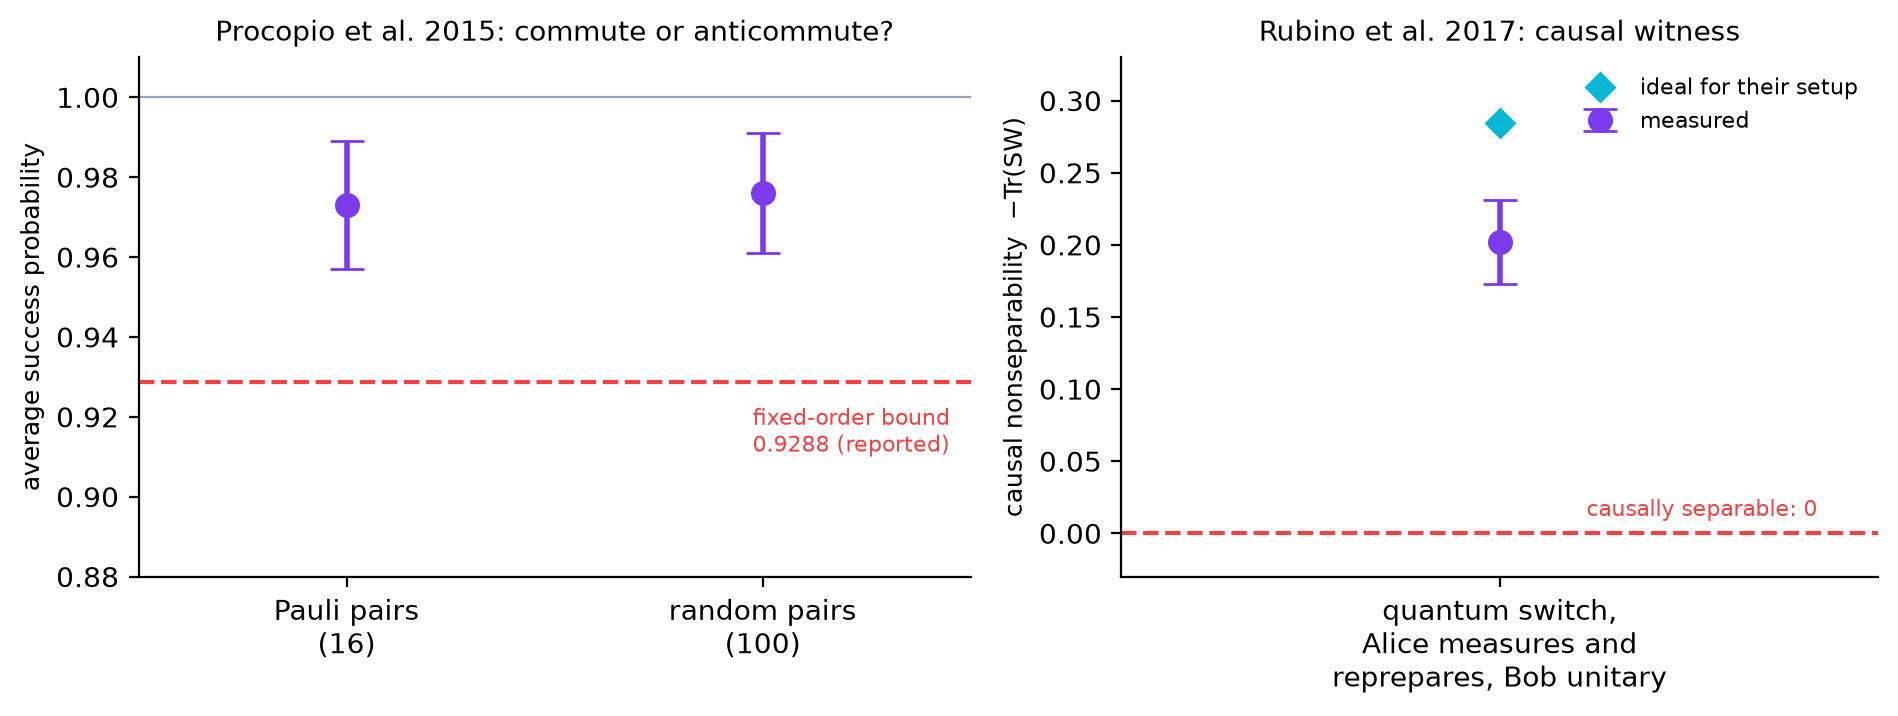

In [4]:
_show_mpl(_lessonfigs.experiments_figure())

*Reported numbers (arXiv versions). Left: average success in the commute-or-anticommute task, with the fixed-order bound that Procopio et al. computed. Right: the causal nonseparability $-\operatorname{Tr}(SW)$ measured by Rubino et al., with the ideal value for their setup; any causally separable process gives at most 0.*

:::{caution} What these results do not show
(1) Neither result is device-independent. A causal witness assumes that the input states, local operations and final measurements are the ones characterized; the inferred process is only as good as that characterization [@process; @rubino]. (2) No causal inequality was violated, and none can be with the switch [@process]. (3) Nothing was sent to anyone's past; every probability here is a normalized prediction of a valid process. (4) Procopio's evidence is indirect, success in a task that fixed orders cannot match; Rubino and coauthors note that this inferred the absence of a definite order from the success of an algorithm rather than measuring it directly, which is what their witness adds [@rubino]. (5) The simulations in this lesson reproduce ideal predictions; they are not experiments.
:::

## Worked example

:::{admonition} Two Pauli gates and one input
:class: tip

Let $U_A = Y$, $U_B = Z$ and $|\psi\rangle = |0\rangle$. Compute the switch output for control $|+\rangle$, the probability $P(+)$, and compare with a fair coin that chooses the order.

1. Products: $ZY = -iX$ and $YZ = iX$, so $U_AU_B = -U_BU_A$: the gates anticommute.
2. Branches: control $|0\rangle$ gives $U_BU_A|0\rangle = ZY|0\rangle = -iX|0\rangle = -i|1\rangle$; control $|1\rangle$ gives $U_AU_B|0\rangle = YZ|0\rangle = i|1\rangle$.
3. Output: $\frac{1}{\sqrt2}(|0\rangle(-i|1\rangle) + |1\rangle(i|1\rangle)) = -i\,\frac{1}{\sqrt2}(|0\rangle - |1\rangle)|1\rangle = -i|-\rangle|1\rangle$, in agreement with [](#thm-l6-08-disc).
4. Formula: $K = U_A^\dagger U_B^\dagger U_AU_B = YZYZ = (iX)^2 = -1$, so $P(+) = \frac12(1 - 1) = 0$ by [](#eq-l6-08-pplus).
5. Coin: the register is $\frac12|0\rangle\langle 0|\otimes|1\rangle\langle 1| + \frac12|1\rangle\langle 1|\otimes|1\rangle\langle 1|$ (the phases $\mp i$ drop out of each density matrix), so $P(+) = 1/2$ and the target is $|1\rangle$ either way.

**Result.** The coherent switch puts the control in $|-\rangle$ with certainty and leaves the target in $|1\rangle$; the coin gives a useless $1/2$ with the same target state. The information is in the coherence of the control.
:::

## Exercises

**1. (Core)** Let $U_A = U_B = Z$. Compute the switch output for control $|+\rangle$ and any $|\psi\rangle$.

:::{dropdown} Solution
$U_BU_A = U_AU_B = Z^2 = 1$, so the output is $\frac{1}{\sqrt2}(|0\rangle + |1\rangle)|\psi\rangle = |+\rangle|\psi\rangle$. The control stays $|+\rangle$, $P(+) = 1$, and the target is unchanged.
:::

**2. (Core)** Let $U_A = H$ (Hadamard) and $U_B = X$. Show that $P(+) = 1/2$ for every input, although the gates neither commute nor anticommute.

:::{dropdown} Solution
$K = H^\dagger X^\dagger HX = (HXH)X = ZX = iY$. For any state, $\langle\psi|iY|\psi\rangle$ is purely imaginary because $Y$ is Hermitian, so $\operatorname{Re}\langle\psi|K|\psi\rangle = 0$ and $P(+) = 1/2$ by [](#eq-l6-08-pplus). With $H = (X + Z)/\sqrt2$, $\{H, X\} = \sqrt2\,1 \ne 0$ and $[H, X] = (ZX - XZ)/\sqrt2 = \sqrt2\,iY \ne 0$, so the gates neither commute nor anticommute. Directly from [](#eq-l6-08-output), the $|+\rangle$ component is $\frac12\sqrt2\,|\psi\rangle$, giving $P(+) = 1/2$ again.
:::

**3. (Stretch)** For $U_A = X$ and $U_B = \cos\beta\,X + \sin\beta\,Z$, show that $U_B$ is unitary, that $\{U_A, U_B\} = 2\cos\beta\,1$, and hence that $P(+) = \cos^2\beta$ for every input. What is the target state when the outcome is $+$?

:::{dropdown} Solution
$U_B$ is Hermitian and $U_B^2 = \cos^2\beta\,X^2 + \sin^2\beta\,Z^2 + \cos\beta\sin\beta(XZ + ZX) = 1$ because $XZ = -ZX$; so it is unitary. $\{X, U_B\} = 2\cos\beta\,X^2 + \sin\beta(XZ + ZX) = 2\cos\beta\,1$. By [](#eq-l6-08-output) the $|+\rangle$ component is $\frac12\cdot 2\cos\beta|\psi\rangle$, so $P(+) = \cos^2\beta$ and, given $+$, the target is $|\psi\rangle$ itself (up to the sign of $\cos\beta$).
:::

**4. (Stretch)** The control loses coherence by a factor $V = 0.9$ before it is measured. Using the rule "anticommute if the outcome is $-$", what is the error probability for an anticommuting pair, and for a commuting pair? How many independent repetitions with a majority vote make the error below $10^{-3}$?

:::{dropdown} Solution
For anticommuting gates $P(-) = (1 + V)/2 = 0.95$, so the error is $0.05$. For commuting gates $K = 1$, $P(+) = (1 + V)/2 = 0.95$, error $0.05$. With $n$ odd repetitions the majority errs if at least $(n+1)/2$ runs err: $n = 3$ gives $3(0.05)^2(0.95) + 0.05^3 \approx 0.00725$; $n = 5$ gives $10(0.05)^3(0.95)^2 + 5(0.05)^4(0.95) + 0.05^5 \approx 0.00116$; $n = 7$ gives about $0.00019$. So 7 repetitions, each using each gate once.
:::

**5. (Challenge)** Prove that the switch of two channels does not depend on the choice of Kraus operators, by examining each block of the output in the control basis.

:::{dropdown} Solution
Write the output as a 2 x 2 block matrix in the control basis with input $\rho_c\otimes\rho$. The $(0,0)$ block is $\langle 0|\rho_c|0\rangle\sum_{i,j}B_jA_i\rho A_i^\dagger B_j^\dagger = \langle 0|\rho_c|0\rangle(\mathcal B\circ\mathcal A)(\rho)$, which depends only on the channels; likewise the $(1,1)$ block. The $(0,1)$ block is $\langle 0|\rho_c|1\rangle\sum_{i,j}B_jA_i\rho B_j^\dagger A_i^\dagger$. Replace $A_i$ by $A'_k = \sum_i u_{ki}A_i$ with $u$ unitary (any two Kraus representations of the same channel are related this way after padding the shorter one with zero operators). The $(0,1)$ block becomes $\sum_j\sum_{i,i'}\big(\sum_k u_{ki}\bar u_{ki'}\big)B_jA_i\rho B_j^\dagger A_{i'}^\dagger = \sum_{i,j}B_jA_i\rho B_j^\dagger A_i^\dagger$, because $\sum_k u_{ki}\bar u_{ki'} = (u^\dagger u)_{i'i} = \delta_{ii'}$. The same argument applies to $\{B_j\}$. So all blocks are unchanged.
:::

**6. (Challenge)** Show that $\operatorname{Tr}W_{\rm switch} = 8$, and explain why a measurement of $F_c$ in the $\{|0\rangle, |1\rangle\}$ basis can never reveal causal nonseparability, whatever Alice and Bob do.

:::{dropdown} Solution
Each identity wire has $\langle\!\langle 1|1\rangle\!\rangle = 2$, so each branch vector has squared norm $2^3 = 8$; the branches are orthogonal (different $F_c$), so $\langle w|w\rangle = \frac12(8 + 8) = 8$. This is the normalization $\operatorname{Tr}W = d_Pd_{A_O}d_{B_O} = 8$: with the past prepared in $\rho = 1/d_P$, both local maps maximally mixing (pairing operators $1/d_{A_O}$ and $1/d_{B_O}$) and the future traced out, the total probability is $\operatorname{Tr}W/8 = 1$. A $\{|0\rangle, |1\rangle\}$ measurement of $F_c$ has effects $E\otimes|k\rangle\langle k|$, and $\operatorname{Tr}[W(\dots\otimes|k\rangle\langle k|)]$ only involves the diagonal blocks $\langle k|W|k\rangle$, which are the two fixed-order wirings with weight 1/2. All such statistics are those of the separable mixture of [](#prop-l6-08-trace), so they cannot certify nonseparability.
:::

## Check your understanding

**1. The gates anticommute and the switch's control starts in $|+\rangle$. What does a measurement of the control in the $\{|+\rangle, |-\rangle\}$ basis give?**

- **A.** It depends on the input state
- **B.** Each outcome with probability 1/2
- **C.** $-$ with certainty
- **D.** $+$ with certainty

:::{dropdown} Show the answer
**C. $-$ with certainty**

For $U_AU_B = -U_BU_A$ the anticommutator vanishes and the output is $|-\rangle\otimes U_BU_A|\psi\rangle$, for every input.
:::

**2. A fair coin decides the order and the result is written in a classical register. What is $P(+)$ when the register is measured in the $\{|+\rangle, |-\rangle\}$ basis?**

- **A.** 1/2 for every pair of gates
- **B.** 0 for anticommuting gates
- **C.** $\cos^2\beta$
- **D.** 1 for commuting gates

:::{dropdown} Show the answer
**A. 1/2 for every pair of gates**

The register is diagonal in $\{|0\rangle, |1\rangle\}$, and each of those states gives $+$ with probability 1/2. Without coherence between the orders there is no interference.
:::

**3. What did the causal-witness measurement of Rubino et al. establish?**

- **A.** A device-independent violation of a causal inequality
- **B.** That every quantum process has an indefinite order
- **C.** That the implemented process is causally nonseparable, assuming the operations were as characterized
- **D.** That a message reached an earlier time

:::{dropdown} Show the answer
**C. That the implemented process is causally nonseparable, assuming the operations were as characterized**

A witness is device-dependent: it relies on known inputs, operations and measurements. The switch cannot violate causal inequalities, and nothing in the experiment signals to the past.
:::

**4. A positive operator with the correct trace gives total probability 4 for one choice of local channels. Is it a valid process matrix?** *(Review of [L6-07](#lesson-l6-07))*

- **A.** Only if it is causally separable
- **B.** Yes, positivity and trace are enough
- **C.** Yes, if it also gives 1 for some other choice
- **D.** No: probabilities must sum to 1 for every choice of local channels

:::{dropdown} Show the answer
**D. No: probabilities must sum to 1 for every choice of local channels**

Normalization must hold for every pair of local CPTP maps; the loop operator of L6-07 is an example that is positive with the right trace but gives 4 or 0.
:::

## Common misconceptions

- **"Any order-dependent output proves indefinite causal order."** A definite but unknown order, or a coin that picks the order, also gives order-dependent outputs. What a mixture cannot reproduce is the interference read out from a coherent control, and certifying that requires a witness or a task bound with stated assumptions.
- **"The quantum switch violates causal inequalities, like the OCB process."** Araújo and coauthors showed that the switch does not violate any causal inequality; it is causally nonseparable, which can be certified with a causal witness under characterized operations [@process].
- **"The switch lets one party send a message into the past."** The switch is a valid process: all probabilities are normalized for every choice of local operations, and each route respects its own order. Nothing reaches an earlier laboratory than the wiring allows.

:::{caution} Scope and limits
Everything here assumes ideal, noiseless gates and perfect control coherence unless a parameter $V$ is stated. The fixed-order bound $0.9288$ and the impossibility of perfect fixed-order discrimination are quoted from Procopio et al., who cite Chiribella [@chiribella2012] for the latter; they are not derived here. The experimental numbers are taken from the arXiv versions of the two papers. The process vector uses the transpose-of-Choi pairing convention of [L6-07](#lesson-l6-07); other conventions change the formulas.
:::

:::{seealso} Where this leads
The switch is the standard example of a causally nonseparable process that admits no causal-inequality violation, which sharpens the contrast of [L6-06](#lesson-l6-06) between operator witnesses and device-independent tests. The lab computes the switch of two noisy channels, where the control keeps coherence even when each fixed order outputs pure noise. Quantum counterfactual questions follow in [L6-09](#lesson-l6-09), and the design of a quantum causal experiment in [L6-10](#lesson-l6-10) uses the same discipline of stating assumptions before claims.
:::

:::{dropdown} For instructors

**Why this lesson.** The switch is where students first see a physical procedure described by a causally nonseparable process. The commute-or-anticommute task makes the effect concrete, and the contrast with a coin-chosen order plus the reading of two experiments teaches the habit of separating a computation, a task advantage, and a certification [@switch; @procopio; @rubino].

**Teaching notes.**

- Before the derivation, ask students to predict $P(+)$ for $U_A = X$, $U_B = Z$ with a coin that picks the order; most say it depends on the gates. The answer 1/2 sets up the coherent case.
- Do the worked example on the board with explicit vectors; the phases $\mp i$ are where students go wrong.
- Use the interactive to show that $P(+)$ is independent of the input for the Pauli family, then ask for a pair where it depends on the input (Haar-random unitaries in the code block).
- Spend time on the caution callout: have students sort the five statements into computed, demonstrated in a task, certified with assumptions, and not shown.

**Assessment.** The second stretch exercise (repetitions under dephasing) and the second challenge exercise (why the $F_c$ basis matters) test whether students can connect the algebra to resource and certification claims; the check questions cover the core facts and one review item on validity.

**Going further.** Read the switch sections of [@process] and write down the witness constraints for the switch scenario. Compare with [@maclean], which realizes a coherent mixture of two different causal structures (common cause and cause-effect) rather than of two orders, and state precisely what is superposed in each experiment.

:::

## References

This lesson draws on [@switch; @chiribella; @process; @procopio; @rubino; @ocb; @chiribella2012; @maclean].

**Further reading.**

- [@switch]: The original definition of the switch as a higher-order operation.
- [@procopio]: The commute-or-anticommute experiment with path control and polarization target; the appendix contains the fixed-order bound.
- [@rubino]: The causal-witness experiment, including the measure-and-reprepare operation inside the switch.
- [@maclean]: A related photonic experiment on coherent mixtures of causal relations.

**Next:** [L6-09 · Quantum counterfactual questions](#lesson-l6-09)
